# Credit Card Fraud: What Makes a Transaction Fraudulent?

This dataset holds card transactions. Each one is labeled as fraud or not fraud. The data came from Kaggle: [Credit Card Fraud](https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud/data).

**data/card_transdata.csv**
- **`distance_from_home`**: how far from home the transaction happened
- **`distance_from_last_transaction`**: how far from the previous transaction it happened
- **`ratio_to_median_purchase_price`**: purchase price divided by the cardholder's median purchase price
- **`repeat_retailer`**: 1 if the transaction happened at a retailer the cardholder has used before
- **`used_chip`**: 1 if the card's chip was used
- **`used_pin_number`**: 1 if a PIN was entered
- **`online_order`**: 1 if it was an online order
- **`fraud`**: 1 if the transaction was fraudulent

**Goal:** clean the data, explore it with visualizations, and answer the question: **What makes a transaction fraud?**

**AI system and version used:** Claude Opus 5.5

**Prompt:**

> This is called an AI assignment. The goal is to take the dataset and create a notebook based off of it. Right now in this class I have only used plt, px, sns, pd, and sklearn, so those are the tools you have in your toolbox. Obviously this data is about credit card fraud and finding out what makes credit card fraud. I was explicitly told not to go to the ML side of things.

## Load the data

In [1]:
# Import necessary packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cards = pd.read_csv('data/card_transdata.csv')
print(cards.shape)
cards.head()

(999, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


In [2]:
cards.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [3]:
cards.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_from_home,999.0,26.876607,63.899697,0.104184,3.990543,10.340321,25.393952,965.910612
distance_from_last_transaction,996.0,5.437319,35.668094,0.001448,0.306441,0.958539,3.137259,990.070315
ratio_to_median_purchase_price,997.0,1.655069,2.351386,0.016933,0.468123,0.955504,1.922025,36.074366
repeat_retailer,992.0,0.892137,0.310364,0.000000,1.000000,1.000000,1.000000,1.000000
used_chip,995.0,0.313568,0.464176,0.000000,0.000000,0.000000,1.000000,1.000000
used_pin_number,997.0,0.117352,0.322001,0.000000,0.000000,0.000000,0.000000,1.000000
online_order,995.0,0.673367,0.469218,0.000000,0.000000,1.000000,1.000000,1.000000
fraud,999.0,0.079079,0.269997,0.000000,0.000000,0.000000,0.000000,1.000000


**Prompt:**

> We need to find the missing values.

## Find the missing values
`isna().sum()` counts the empty cells in each column.

In [4]:
missing = cards.isna().sum()
print(missing)
print('Total missing values:', missing.sum())
print('Rows with at least one missing value:', cards.isna().any(axis=1).sum())

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64
Total missing values: 22
Rows with at least one missing value: 22


**Prompt:**

> Drop the rows with null values.

## Drop the rows with null values
Only a small share of rows have a missing value, so dropping them won't change the overall picture.

In [5]:
rows_before = len(cards)
cards = cards.dropna()
rows_after = len(cards)

print('Rows before:', rows_before)
print('Rows after: ', rows_after)
print('Rows dropped:', rows_before - rows_after)
print('Missing values left:', cards.isna().sum().sum())

Rows before: 999
Rows after:  977
Rows dropped: 22
Missing values left: 0


In [6]:
# The yes/no columns were read as floats because of the blanks; now they can be integers again
binary_cols = ['repeat_retailer', 'used_chip', 'used_pin_number', 'online_order', 'fraud']
cards[binary_cols] = cards[binary_cols].astype(int)

# Check for duplicate rows too
print('Duplicate rows:', cards.duplicated().sum())
cards.head()

Duplicate rows: 0


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1,1,0,0,0
3,2.247564,5.600044,0.362663,1,1,0,1,0
4,44.190936,0.566486,2.222767,1,1,0,1,0
5,5.586408,13.261073,0.064768,1,0,0,0,0
6,3.724019,0.956838,0.278465,1,0,0,1,0


**Prompt:**

> After the cell where I drop the rows with missing values, add simple count plots, one variable at a time, for the fraud, used_pin_number, repeat_retailer, and online_order columns, each with a clear title. Next, add a plain histogram of ratio_to_median_purchase_price and a histogram of distance_from_home.

## Look at one variable at a time
Before comparing anything, check what each column looks like on its own.

### Fraud
How many transactions are fraud (1) and how many are not (0).

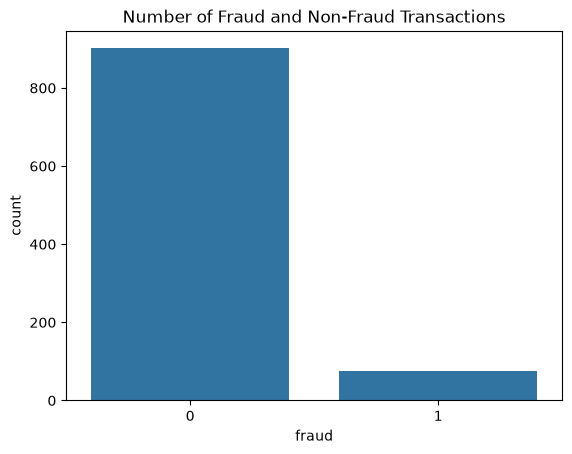

In [7]:
sns.countplot(data=cards, x='fraud')
plt.title('Number of Fraud and Non-Fraud Transactions')
plt.show()

### Used PIN number
How many transactions had a PIN entered (1) versus not (0).

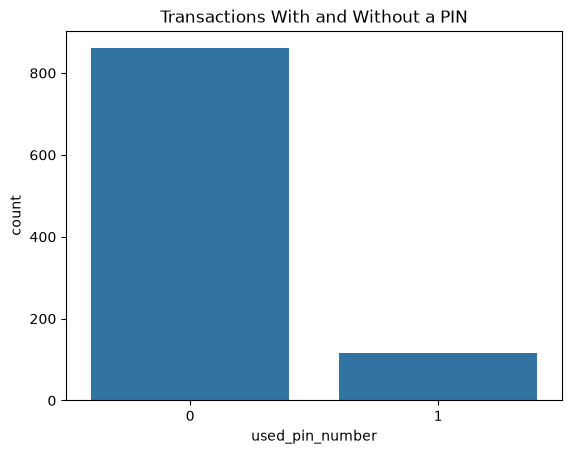

In [8]:
sns.countplot(data=cards, x='used_pin_number')
plt.title('Transactions With and Without a PIN')
plt.show()

### Repeat retailer
How many transactions were at a store the cardholder had used before (1) versus a new one (0).

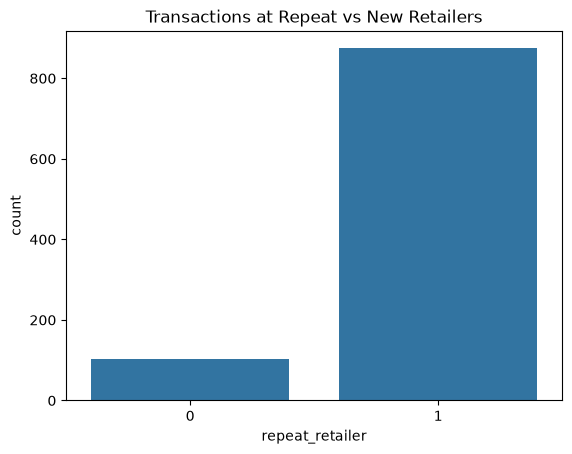

In [9]:
sns.countplot(data=cards, x='repeat_retailer')
plt.title('Transactions at Repeat vs New Retailers')
plt.show()

### Online order
How many transactions were online orders (1) versus in person (0).

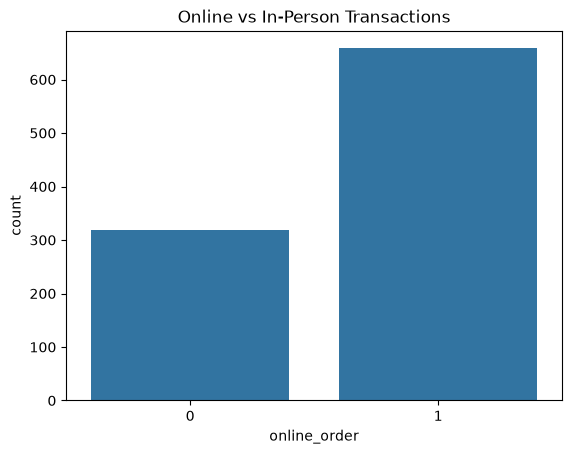

In [10]:
sns.countplot(data=cards, x='online_order')
plt.title('Online vs In-Person Transactions')
plt.show()

### Ratio to median purchase price
A plain histogram of how big each purchase was compared to the cardholder's usual purchase. Most sit near 1, with a long tail to the right.

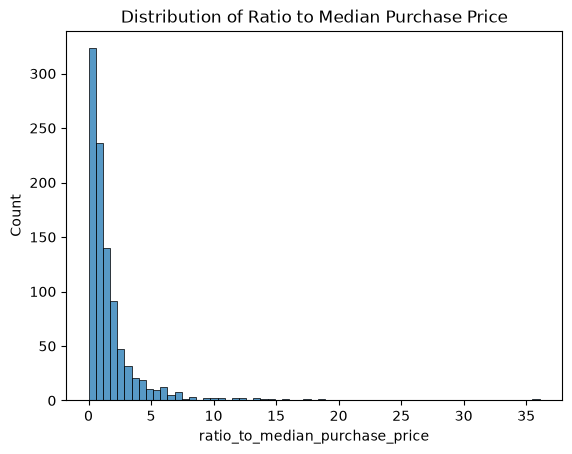

In [11]:
sns.histplot(data=cards, x='ratio_to_median_purchase_price')
plt.title('Distribution of Ratio to Median Purchase Price')
plt.show()

### Distance from home (YOUTRY)
A histogram of how far from home each transaction happened. Most are close to home, with a few very far away.

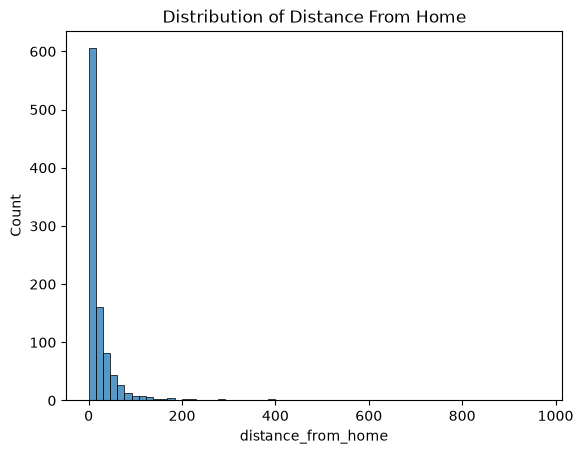

In [12]:
sns.histplot(data=cards, x='distance_from_home')
plt.title('Distribution of Distance From Home')
plt.show()

**Prompt:**

> Add a short markdown cell explaining that it's more useful to see how fraud and non-fraud transactions break down across each variable. For used_pin_number, used_chip, and online_order, make two charts each: a count plot split by fraud using green for non-fraud and red for fraud, and a stacked bar chart of the percentage of fraud vs non-fraud in each group.

## Break each variable down by fraud
Counting each column on its own shows what is common, but not what is linked to fraud. It is more useful to split every variable into fraud and non-fraud transactions and see where fraud shows up more often. For each yes/no column below there are two charts: a count plot split by fraud (green = not fraud, red = fraud), and a stacked bar showing what percent of each group is fraud.

### Used PIN number
Count of transactions with and without a PIN, split by fraud.

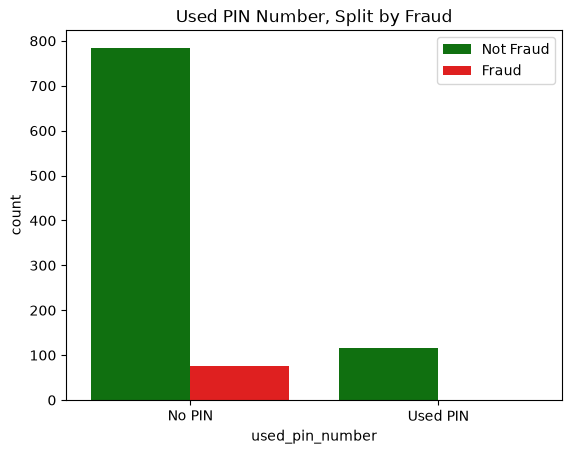

In [13]:
# Labels and colors reused by the charts in this section
fraud_names = {0: 'Not Fraud', 1: 'Fraud'}
fraud_colors = {'Not Fraud': 'green', 'Fraud': 'red'}

sns.countplot(data=cards, x='used_pin_number', hue=cards['fraud'].map(fraud_names), palette=fraud_colors)
plt.title('Used PIN Number, Split by Fraud')
plt.xticks([0, 1], ['No PIN', 'Used PIN'])
plt.legend(title='')
plt.show()

Percent of fraud vs non-fraud inside each PIN group, so the two groups can be compared even though they are different sizes.

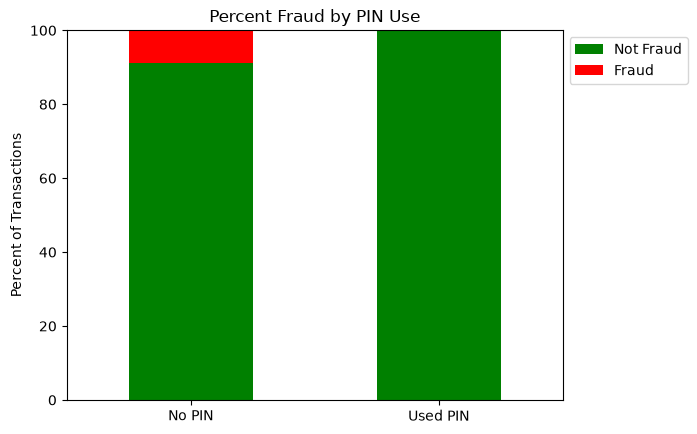

fraud,Not Fraud,Fraud
used_pin_number,,
No PIN,91.2,8.8
Used PIN,100.0,0.0


In [14]:
pin_pct = pd.crosstab(cards['used_pin_number'], cards['fraud'], normalize='index') * 100
pin_pct = pin_pct.rename(index={0: 'No PIN', 1: 'Used PIN'}, columns=fraud_names)

pin_pct.plot(kind='bar', stacked=True, color=['green', 'red'])
plt.title('Percent Fraud by PIN Use')
plt.xlabel('')
plt.ylabel('Percent of Transactions')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

pin_pct.round(1)

### Used chip
Count of transactions with and without the chip, split by fraud.

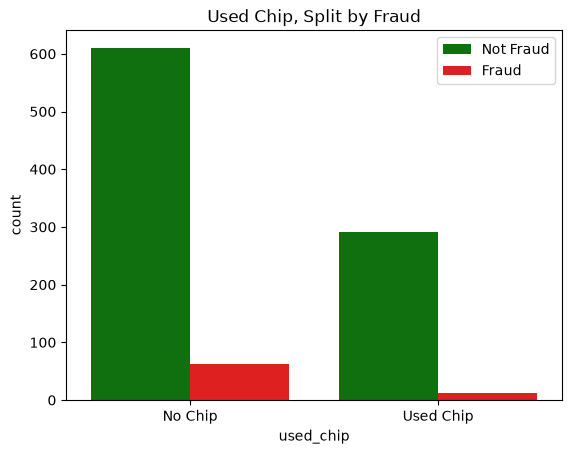

In [15]:
sns.countplot(data=cards, x='used_chip', hue=cards['fraud'].map(fraud_names), palette=fraud_colors)
plt.title('Used Chip, Split by Fraud')
plt.xticks([0, 1], ['No Chip', 'Used Chip'])
plt.legend(title='')
plt.show()

Percent of fraud vs non-fraud inside each chip group.

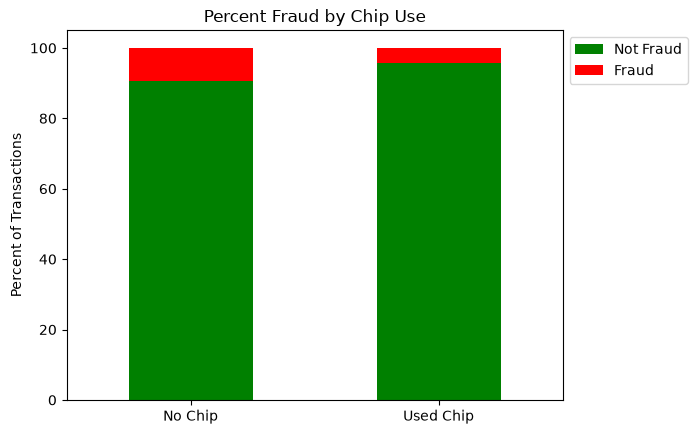

fraud,Not Fraud,Fraud
used_chip,,
No Chip,90.6,9.4
Used Chip,95.7,4.3


In [16]:
chip_pct = pd.crosstab(cards['used_chip'], cards['fraud'], normalize='index') * 100
chip_pct = chip_pct.rename(index={0: 'No Chip', 1: 'Used Chip'}, columns=fraud_names)

chip_pct.plot(kind='bar', stacked=True, color=['green', 'red'])
plt.title('Percent Fraud by Chip Use')
plt.xlabel('')
plt.ylabel('Percent of Transactions')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

chip_pct.round(1)

### Online order (YOUTRY)
Count of online and in-person transactions, split by fraud.

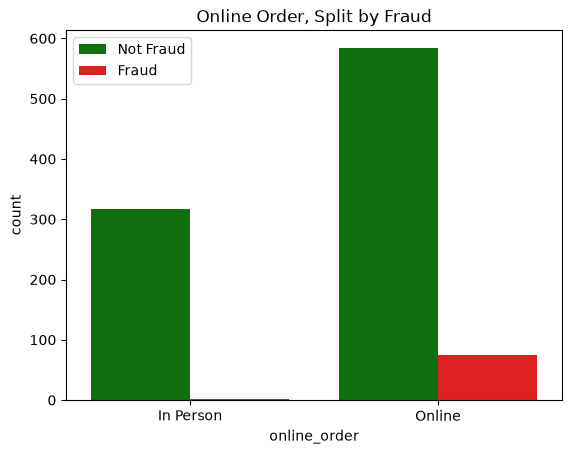

In [17]:
sns.countplot(data=cards, x='online_order', hue=cards['fraud'].map(fraud_names), palette=fraud_colors)
plt.title('Online Order, Split by Fraud')
plt.xticks([0, 1], ['In Person', 'Online'])
plt.legend(title='')
plt.show()

Percent of fraud vs non-fraud for online and in-person transactions (YOUTRY).

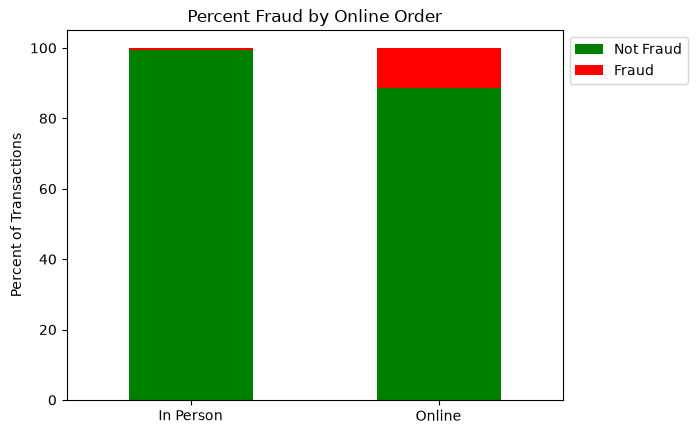

fraud,Not Fraud,Fraud
online_order,,
In Person,99.4,0.6
Online,88.8,11.2


In [18]:
online_pct = pd.crosstab(cards['online_order'], cards['fraud'], normalize='index') * 100
online_pct = online_pct.rename(index={0: 'In Person', 1: 'Online'}, columns=fraud_names)

online_pct.plot(kind='bar', stacked=True, color=['green', 'red'])
plt.title('Percent Fraud by Online Order')
plt.xlabel('')
plt.ylabel('Percent of Transactions')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

online_pct.round(1)

**Prompt:**

> Add a seaborn scatter plot of distance_from_last_transaction vs ratio_to_median_purchase_price colored by fraud. Put a short markdown note above each new code cell explaining what it shows.

## Two numeric variables at once

### Distance from last transaction vs purchase size (YOUTRY)
Each dot is a transaction, colored green for not fraud and red for fraud.

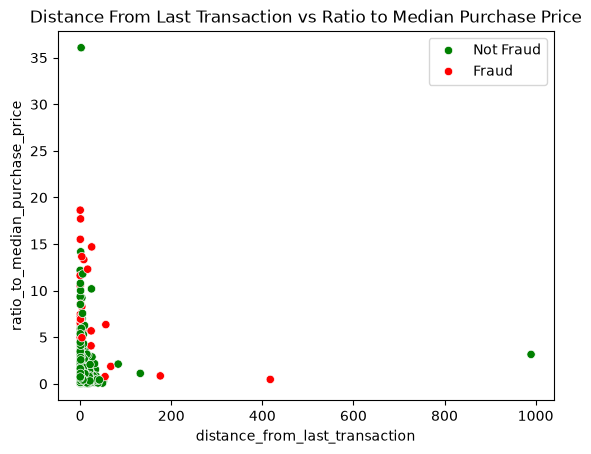

In [19]:
sns.scatterplot(data=cards, x='distance_from_last_transaction', y='ratio_to_median_purchase_price',
                hue=cards['fraud'].map(fraud_names), palette=fraud_colors)
plt.title('Distance From Last Transaction vs Ratio to Median Purchase Price')
plt.legend(title='')
plt.show()

### Distance from home vs purchase size
Same idea using distance from home. The red fraud points sit mostly at high purchase ratios or far distances.

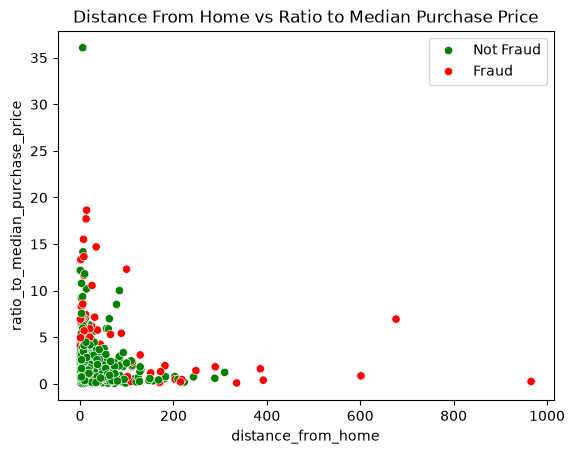

In [20]:
sns.scatterplot(data=cards, x='distance_from_home', y='ratio_to_median_purchase_price',
                hue=cards['fraud'].map(fraud_names), palette=fraud_colors)
plt.title('Distance From Home vs Ratio to Median Purchase Price')
plt.legend(title='')
plt.show()